[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ContextLab/timecorr/blob/master/docs/tutorial/quickstart.ipynb)

# Quickstart

This notebook shows the three main calls: `tc.timecorr` on one dataset, the same call on several subjects, and `tc.features` for higher orders. Each step ends with a plot.

In [1]:
# On Google Colab, install timecorr (this cell does nothing elsewhere): release 0.3.1 or
# later from PyPI, or, when pip cannot install that (it then prints an error first),
# the master branch on GitHub.
import sys

if 'google.colab' in sys.modules:
    !pip install -q "timecorr>=0.3.1" || pip install -q "timecorr @ git+https://github.com/ContextLab/timecorr.git@master"

In [2]:
import numpy as np
import matplotlib.pyplot as plt

import timecorr as tc

%matplotlib inline
# one style for every tutorial: colorblind-safe colors (Okabe-Ito)
plt.style.use('timecorr.tutorial')
COLORS = plt.rcParams['axes.prop_cycle'].by_key()['color']

## 1. Data with known correlations

`tc.simulate_data` draws data whose correlations change over time. With `return_corrs=True` it also returns the true correlations, so we can check the estimates.

In [3]:
data, truth = tc.simulate_data(datagen='block', T=300, K=8, B=3,
                               return_corrs=True, set_random_seed=1)
print('data (timepoints, features):', data.shape)

data (timepoints, features): (300, 8)


## 2. Dynamic correlations of one dataset

`tc.timecorr` estimates a correlation matrix at every timepoint. Each row of the output is one matrix in vectorized form; `tc.vec2mat` turns it back into a `K x K x T` array. The plot compares one pair of features with the truth.

output (timepoints, entries): (300, 36)


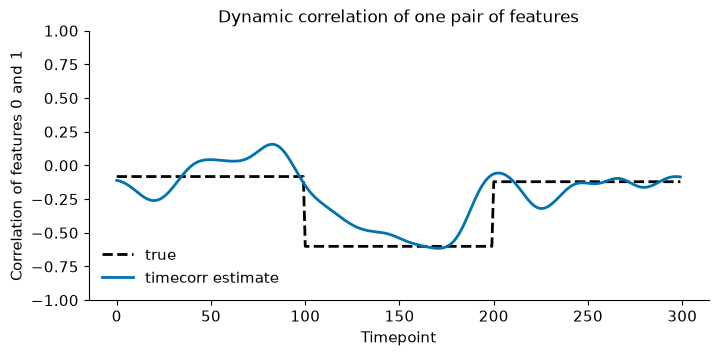

In [4]:
corrs = tc.timecorr(data, weights_params={'var': 100})
print('output (timepoints, entries):', corrs.shape)

est, true = tc.vec2mat(corrs), tc.vec2mat(truth)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(true[0, 1], color='k', ls='--', lw=2, label='true')
ax.plot(est[0, 1], lw=2, label='timecorr estimate')
ax.set(xlabel='Timepoint', ylabel='Correlation of features 0 and 1', ylim=(-1, 1),
       title='Dynamic correlation of one pair of features')
ax.legend(loc='lower left')
plt.show()

## 3. Several subjects

Pass a list with one array per subject. Here every subject shares the true correlations, so we estimate each subject's own correlations (`cfun=tc.autofc`) and average them (`combine=tc.corrmean_combine`).

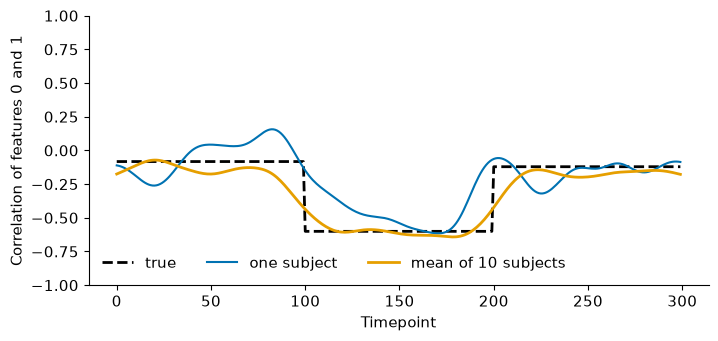

In [5]:
subjects, subject_truth = tc.simulate_data(datagen='block', S=10, T=300, K=8, B=3,
                                           return_corrs=True, set_random_seed=1)
group = tc.timecorr(subjects, cfun=tc.autofc, combine=tc.corrmean_combine,
                    weights_params={'var': 100})
one = tc.timecorr(subjects[0], weights_params={'var': 100})

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(tc.vec2mat(subject_truth[0])[0, 1], color='k', ls='--', lw=2, label='true')
ax.plot(tc.vec2mat(one)[0, 1], lw=1.5, label='one subject')
ax.plot(tc.vec2mat(group)[0, 1], lw=2, label='mean of 10 subjects')
ax.set(xlabel='Timepoint', ylabel='Correlation of features 0 and 1', ylim=(-1, 1))
ax.legend(loc='lower left', ncol=3)
plt.show()

## 4. Higher-order features

`tc.features` returns one entry per order. Order 0 is the data, order 1 summarizes the dynamic correlations, and order 2 summarizes the dynamic correlations of features made from order 1 (the [higher-order tutorial](higher_order.ipynb) explains the steps). `tc.simulate_nested` makes suitable data, with two subjects of many nodes whose couplings change together over time.

order 0: 2 subjects, each (1000, 108)
order 1: 2 subjects, each (1000, 108)
order 2: 2 subjects, each (1000, 36)


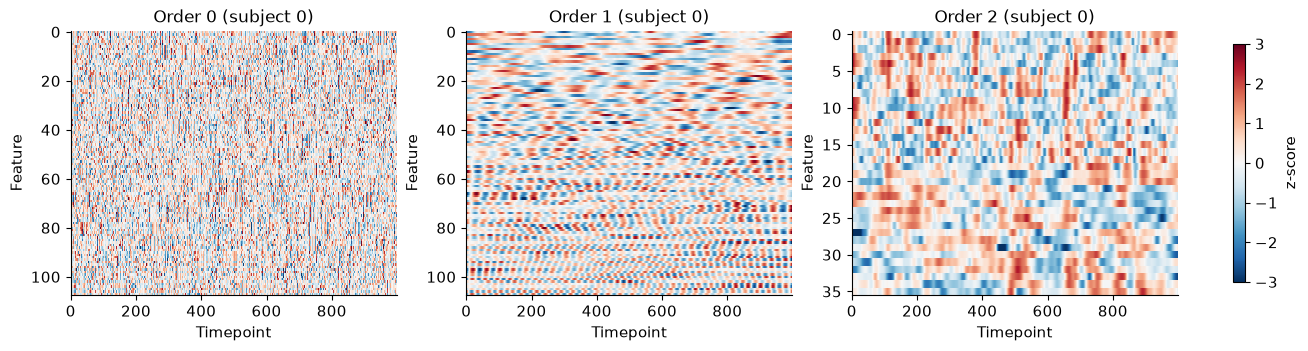

In [6]:
nested, _ = tc.simulate_nested(S=2, T=1000, set_random_seed=0)
X = tc.features(nested, order=2, cfun=tc.autofc)
for k, x in enumerate(X):
    print(f'order {k}: {len(x)} subjects, each {x[0].shape}')

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharex=True, layout='constrained')
for k, ax in enumerate(axes):
    x = X[k][0]
    z = (x - x.mean(0)) / x.std(0)  # each feature z-scored, to share one color scale
    im = ax.imshow(z.T, aspect='auto', cmap='RdBu_r', vmin=-3, vmax=3, interpolation='nearest')
    ax.set(title=f'Order {k} (subject 0)', xlabel='Timepoint', ylabel='Feature')
fig.colorbar(im, ax=axes, label='z-score', shrink=0.9)
plt.show()

## Next steps

- [Kernels](kernels.ipynb): how the kernel sets the time scale of the estimates.
- [Subjects](subjects.ipynb): correlations across subjects and input formats.
- [Reducing features](reduce.ipynb), [simulating data](simulate.ipynb), [higher orders](higher_order.ipynb), [events](events.ipynb) and [decoding](decoding.ipynb).
- Real data: [brain networks](htfa_network_animations.ipynb), [the stock market](stocks.ipynb) and [trajectories](trajectories.ipynb).

The picture on this tutorial's card in the gallery: the true correlation of one pair of features (dashed) and its estimate.

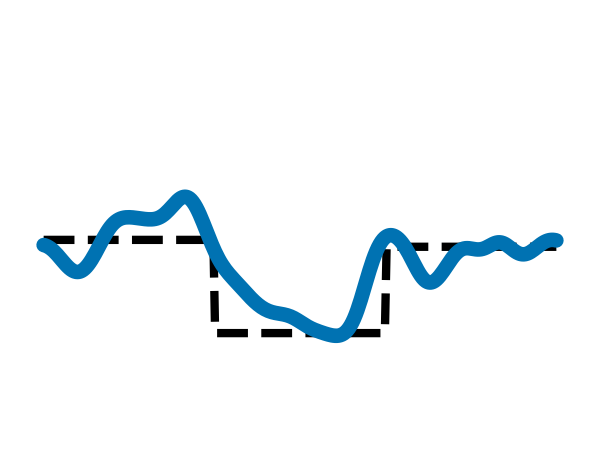

In [7]:
import io
from IPython.display import Image, display

fig = plt.figure(figsize=(4, 3), facecolor='white')
ax = fig.add_axes([0.03, 0.08, 0.94, 0.84])
ax.plot(true[0, 1], color='k', ls='--', lw=4)
ax.plot(est[0, 1], color=COLORS[0], lw=7, solid_capstyle='round')
ax.set_ylim(-1.05, 1.05)
ax.set_axis_off()
buf = io.BytesIO()
fig.savefig(buf, format='png', dpi=150, facecolor='white')
plt.close(fig)
display(Image(buf.getvalue()))